In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"

births = pd.read_csv(url)

print(births.head())
print("Shape:", births.shape)
print(births.dtypes)


   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548
Shape: (15547, 5)
year        int64
month       int64
day       float64
gender     object
births      int64
dtype: object


gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428
gender     ratio  percentage
decade                      
1960    1.052997    5.299738
1970    1.052787    5.278676
1980    1.050960    5.096030
1990    1.048312    4.831239
2000    1.048116    4.811587
Male births exceed female births:
decade
1960    True
1970    True
1980    True
1990    True
2000    True
dtype: bool


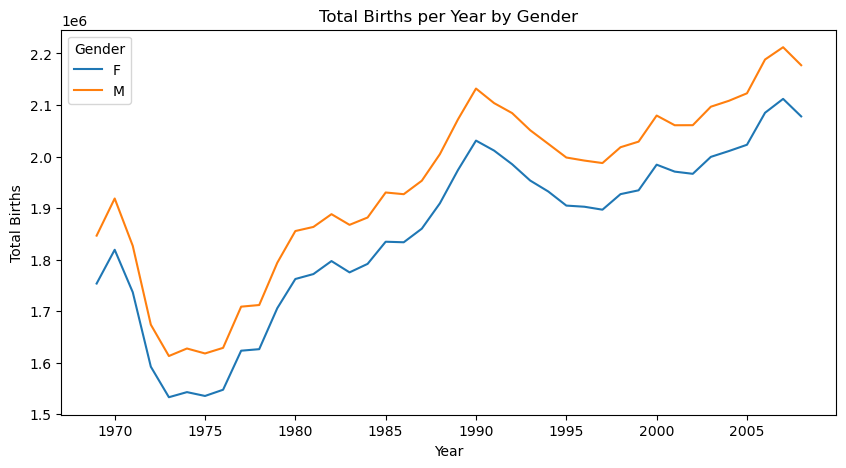

In [2]:

births['decade'] = 10 * (births['year'] // 10)

pivot = births.pivot_table(index='decade',columns='gender',values='births',aggfunc='sum')

print(pivot)

pivot['ratio'] = pivot['M'] / pivot['F']
pivot['percentage'] = ((pivot['M'] - pivot['F']) / pivot['F']) * 100

print(pivot[['ratio', 'percentage']])

print("Male births exceed female births:")
print(pivot['M'] > pivot['F'])

yearly = births.pivot_table(index='year',columns='gender',values='births',aggfunc='sum')

yearly.plot(figsize=(10, 5))
plt.xlabel('Year')
plt.ylabel('Total Births')
plt.title('Total Births per Year by Gender')
plt.legend(title='Gender')
plt.show()


In [3]:

Q1, Q3 = np.percentile(births['births'].dropna(), [25, 75])

mu = births['births'].median()
sig = 0.74 * (Q3 - Q1)

lower = mu - 5 * sig
upper = mu + 5 * sig

original_rows = len(births)

clean_births = births.query('@lower <= births <= @upper').copy()

removed = original_rows - len(clean_births)

print("Median:", mu)
print("Robust standard deviation:", sig)
print("Original rows:", original_rows)
print("Cleaned rows:", len(clean_births))
print("Rows removed:", removed)

clean_births['day'] = clean_births['day'].astype(int)

print(clean_births.dtypes)


Median: 4814.0
Robust standard deviation: 689.31
Original rows: 15547
Cleaned rows: 14610
Rows removed: 937
year       int64
month      int64
day        int32
gender    object
births     int64
decade     int64
dtype: object


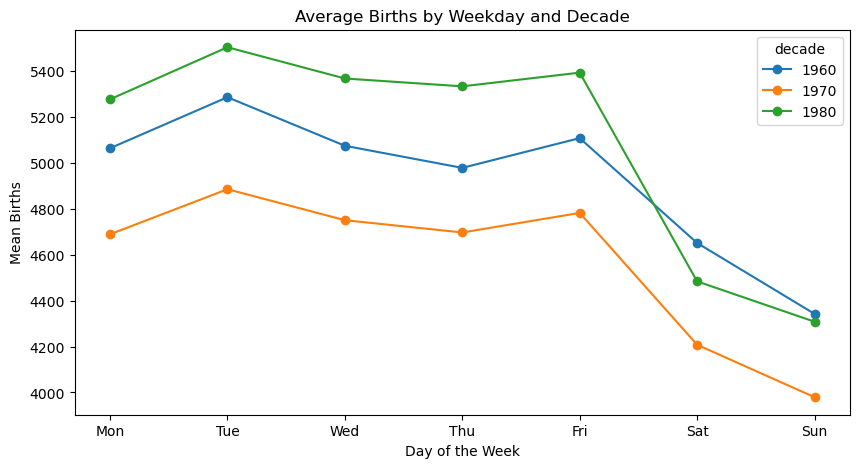

In [4]:

clean_births = clean_births.dropna(subset=['year', 'month', 'day']).copy()

clean_births['day'] = clean_births['day'].astype(int)

clean_births['date'] = pd.to_datetime(clean_births[['year', 'month', 'day']],errors='coerce')

clean_births = clean_births.dropna(subset=['date'])
clean_births = clean_births.set_index('date')

clean_births['dayofweek'] = clean_births.index.dayofweek

weekday_pivot = clean_births.pivot_table(index='dayofweek',columns='decade',values='births',aggfunc='mean')

weekday_pivot = weekday_pivot.reindex(range(7))
weekday_pivot.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

weekday_pivot.plot(figsize=(10, 5), marker='o')
plt.xlabel('Day of the Week')
plt.ylabel('Mean Births')
plt.title('Average Births by Weekday and Decade')
plt.show()


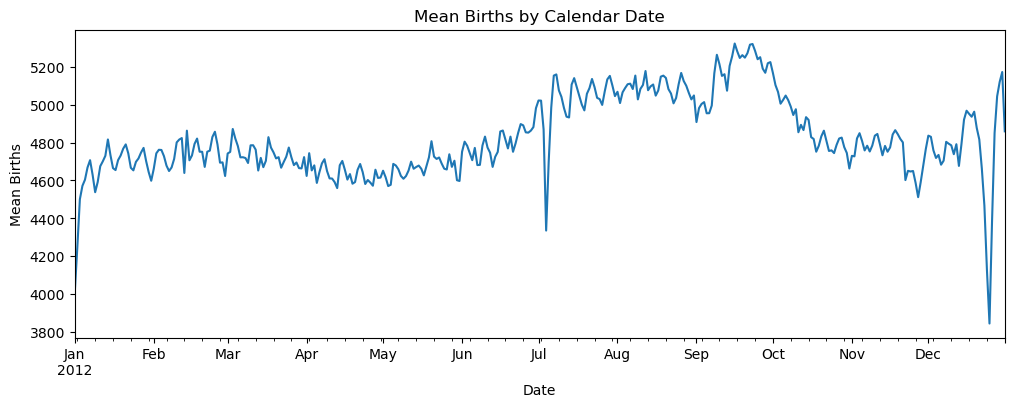

In [5]:

date_pivot = clean_births.pivot_table(index=['month', clean_births.index.day],values='births',aggfunc='mean')

date_pivot.index.names = ['month', 'day']

date_data = date_pivot.reset_index()

date_data['date'] = pd.to_datetime({'year': 2012,'month': date_data['month'],'day': date_data['day']}, errors='coerce')

date_data = date_data.dropna(subset=['date'])
date_data = date_data.sort_values('date')
date_data = date_data.set_index('date')

date_data.plot(y='births',figsize=(12, 4),legend=False)

plt.xlabel('Date')
plt.ylabel('Mean Births')
plt.title('Mean Births by Calendar Date')
plt.show()


In [6]:

lowest_dates = date_data.nsmallest(5, 'births')

print(lowest_dates[['month', 'day', 'births']])


            month  day    births
date                            
2012-12-25     12   25  3844.450
2012-01-01      1    1  4009.225
2012-12-24     12   24  4126.250
2012-01-02      1    2  4247.400
2012-07-04      7    4  4335.325


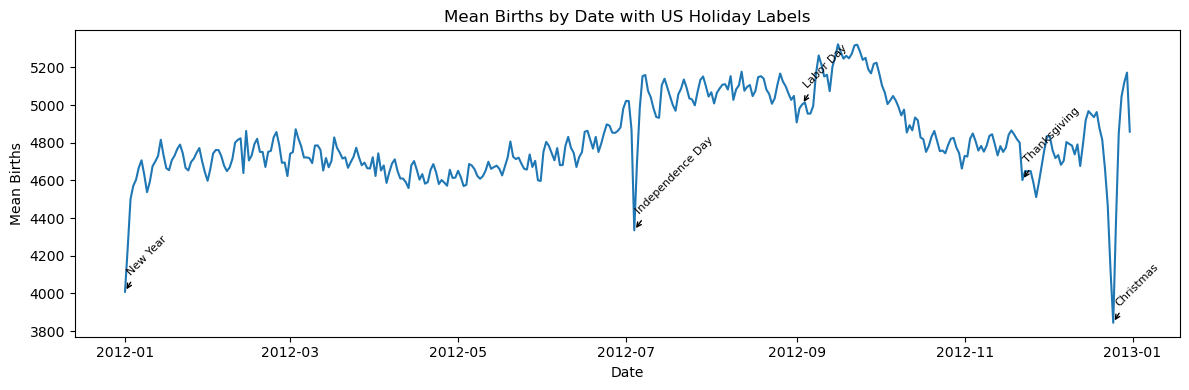

In [7]:

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(date_data.index, date_data['births'])

holidays = {
    'New Year': '2012-01-01',
    'Independence Day': '2012-07-04',
    'Labor Day': '2012-09-03',
    'Thanksgiving': '2012-11-22',
    'Christmas': '2012-12-25'
}

for name, date in holidays.items():
    date = pd.Timestamp(date)
    if date in date_data.index:
        value = date_data.loc[date, 'births']
        ax.annotate(
            name,
            xy=(date, value),
            xytext=(0, 12),
            textcoords='offset points',
            rotation=45,
            ha='left',
            fontsize=8,
            arrowprops={'arrowstyle': '->'}
        )

ax.set_xlabel('Date')
ax.set_ylabel('Mean Births')
ax.set_title('Mean Births by Date with US Holiday Labels')
plt.tight_layout()
plt.show()


In [8]:

group_table = births.groupby(['decade', 'gender'])['births'].sum().unstack()
print(group_table)
print("Tables match:", pivot[['M', 'F']].equals(group_table))


gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428
Tables match: False


In [9]:

%timeit births.pivot_table(index='decade', columns='gender', values='births', aggfunc='sum')


5.44 ms ± 526 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [10]:

%timeit births.groupby(['decade', 'gender'])['births'].sum().unstack()


2.66 ms ± 255 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
